In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Metro_Interstate_Traffic_Volume_snow_updated.csv')

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
df.shape

(48204, 9)

In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.371475,0.101064,49.362231,3259.818355
std,13.338232,1.233681,0.591236,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,16.000000,5.000000,100.000000,7280.000000


**Understand the columns**

In [5]:
df.columns

Index(['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main',
       'weather_description', 'date_time', 'traffic_volume'],
      dtype='str')

In [6]:
df.isnull().sum()

holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

In [7]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing

,Missing_Count,Missing_Percentage
holiday,48143,99.873454
temp,0,0.000000
rain_1h,0,0.000000
snow_1h,0,0.000000
clouds_all,0,0.000000
weather_main,0,0.000000
weather_description,0,0.000000
date_time,0,0.000000
traffic_volume,0,0.000000


In [8]:
df['holiday'].value_counts(dropna=False)

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64

In [9]:
df.duplicated().sum()

np.int64(17)

In [10]:
df.drop_duplicates(inplace=True)

Convert temperature from Kelvin to Celsius

In [11]:
df['temp_celsius'] = df['temp'] - 273.15

In [12]:
df[['temp', 'temp_celsius']].head()

,temp,temp_celsius
0,288.28,15.13
1,289.36,16.21
2,289.58,16.43
3,290.13,16.98
4,291.14,17.99


Convert date_time

In [13]:
df['date_time'] = pd.to_datetime(df['date_time'])

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     str           
 1   temp                 48187 non-null  float64       
 2   rain_1h              48187 non-null  float64       
 3   snow_1h              48187 non-null  float64       
 4   clouds_all           48187 non-null  int64         
 5   weather_main         48187 non-null  str           
 6   weather_description  48187 non-null  str           
 7   date_time            48187 non-null  datetime64[us]
 8   traffic_volume       48187 non-null  int64         
 9   temp_celsius         48187 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(2), str(3)
memory usage: 4.0 MB


In [15]:
df['year'] = df['date_time'].dt.year
df['month'] = df['date_time'].dt.month
df['day'] = df['date_time'].dt.day
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek

In [16]:
df['day_name'] = df['date_time'].dt.day_name()

**Create weekend feature**

In [17]:
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int) #0 → Weekday 1 → Weekend

**Create holiday feature**

In [18]:
df['holiday'] = df['holiday'].fillna('None')

df['is_holiday'] = (df['holiday'] != 'None').astype(int)

In [19]:
print(df['holiday'].value_counts())


holiday
None                         48126
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [20]:
print(df['is_holiday'].value_counts())

is_holiday
0    48126
1       61
Name: count, dtype: int64


Check traffic-volume outliers

C:\Users\SIBY\AppData\Local\Temp\ipykernel_23780\1562990420.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['traffic_volume'], vert=False)


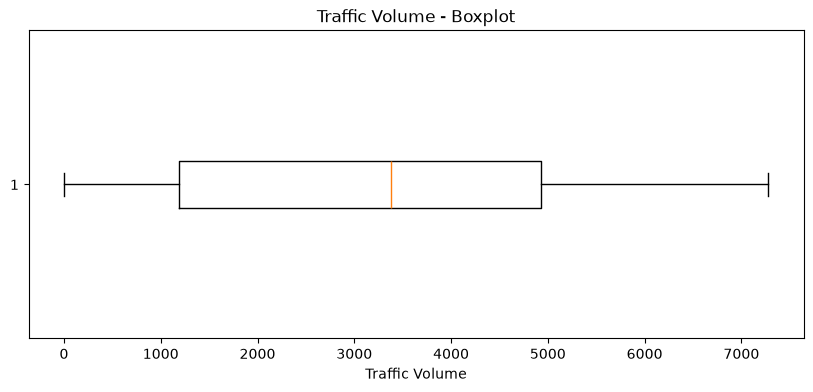

In [21]:
plt.figure(figsize=(10,4))
plt.boxplot(df['traffic_volume'], vert=False)
plt.xlabel('Traffic Volume')
plt.title('Traffic Volume - Boxplot')
plt.show()

**Basic EDA**

**Hourly traffic analysis** #Traffic volume varies significantly by hour, with clear peak periods associated with commuting hours.

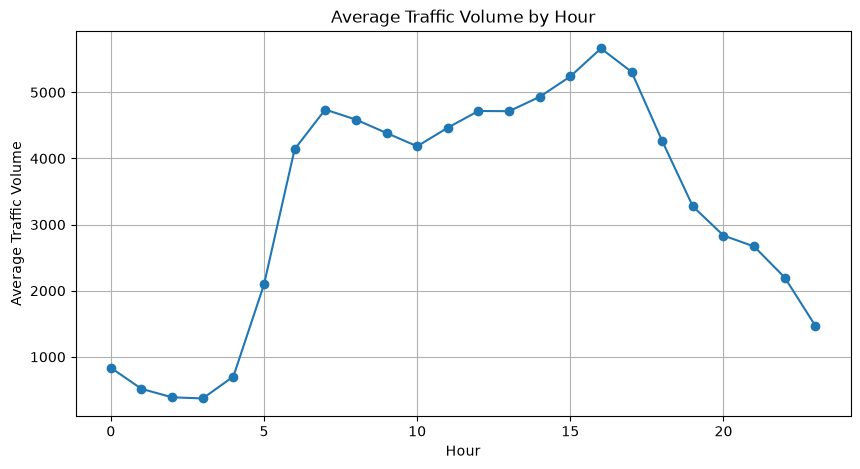

In [22]:
hourly_traffic = df.groupby('hour')['traffic_volume'].mean()

plt.figure(figsize=(10,5))
hourly_traffic.plot(marker='o')

plt.xlabel('Hour')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Hour')
plt.grid()
plt.show()

* Peak Hours: 4 PM, 3 PM, 5 PM
* Week traffic hours: 12-4 AM, 11 PM

**Daily traffic analysis**  #Which day has the highest average traffic?

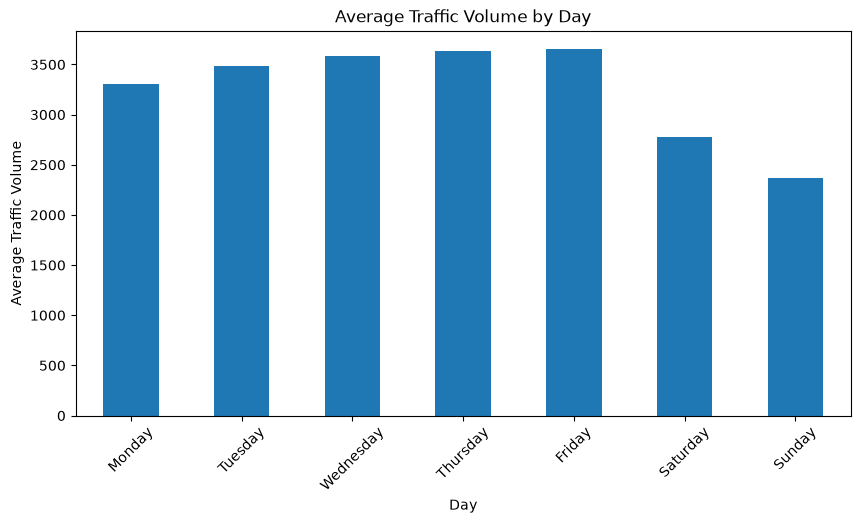

In [23]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

daily_traffic = (
    df.groupby('day_name')['traffic_volume']
      .mean()
      .reindex(day_order)
)

plt.figure(figsize=(10,5))
daily_traffic.plot(kind='bar')

plt.xlabel('Day')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Day')
plt.xticks(rotation=45)
plt.show()

**Weekday vs weekend analysis**    

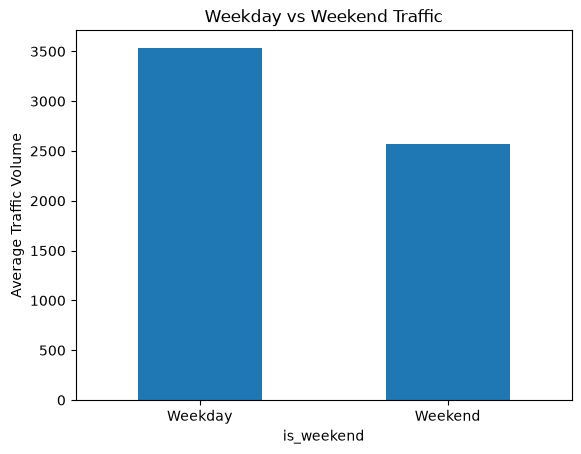

In [24]:
weekend_traffic = df.groupby('is_weekend')['traffic_volume'].mean()

weekend_traffic.plot(kind='bar')

plt.xticks([0,1], ['Weekday', 'Weekend'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Weekday vs Weekend Traffic')
plt.show()

**Monthly traffic pattern**  #This shows whether traffic changes seasonally.

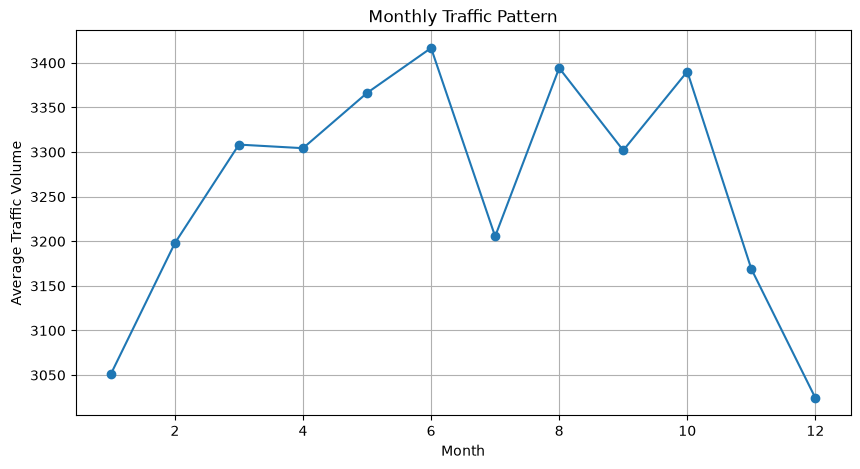

In [25]:
monthly_traffic = df.groupby('month')['traffic_volume'].mean()

monthly_traffic.plot(
    kind='line',
    marker='o',
    figsize=(10,5)
)

plt.xlabel('Month')
plt.ylabel('Average Traffic Volume')
plt.title('Monthly Traffic Pattern')
plt.grid()
plt.show()

**Weather vs traffic analysis**

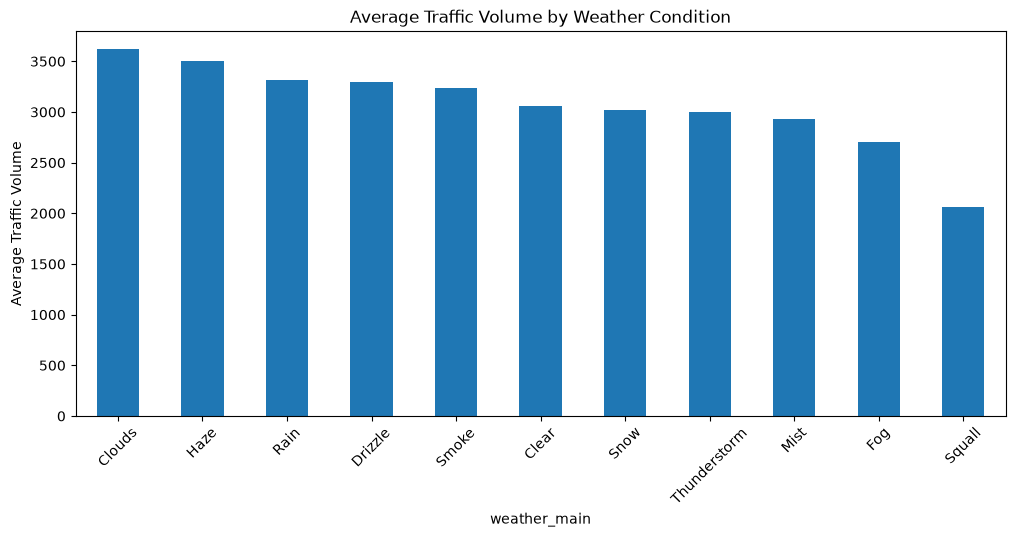

In [26]:
weather_traffic = (
    df.groupby('weather_main')['traffic_volume']
      .mean()
      .sort_values(ascending=False)
)

weather_traffic.plot(
    kind='bar',
    figsize=(12,5)
)

plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Weather Condition')
plt.xticks(rotation=45)
plt.show()

**Rain vs traffic**

Create new feature # **is_raining**

In [27]:
df['is_raining'] = (df['rain_1h'] > 0).astype(int)

In [28]:
df.groupby('is_raining')['traffic_volume'].mean()

is_raining
0    3256.457888
1    3274.308405
Name: traffic_volume, dtype: float64

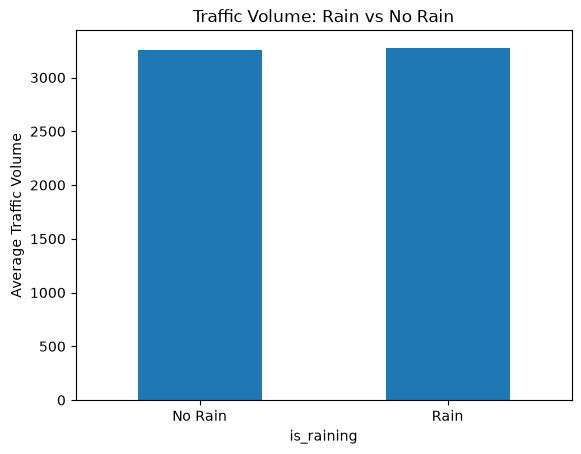

In [29]:
df.groupby('is_raining')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['No Rain', 'Rain'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Traffic Volume: Rain vs No Rain')
plt.show()

**Holiday vs normal-day traffic**

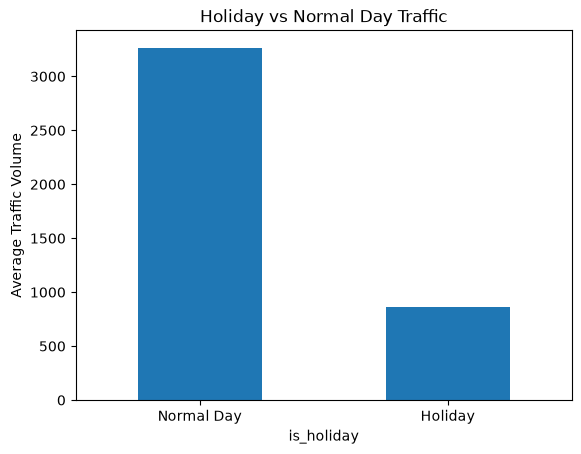

In [30]:
df.groupby('is_holiday')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['Normal Day', 'Holiday'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Holiday vs Normal Day Traffic')
plt.show()

**Create congestion levels**

In [31]:
df['congestion_level'] = pd.qcut(
    df['traffic_volume'],
    q=3,
    labels=['Low', 'Moderate', 'High']
)

In [32]:
df['congestion_level'].value_counts() #This divides the dataset into four approximately equal groups.

congestion_level
Moderate    16065
Low         16063
High        16059
Name: count, dtype: int64

In [33]:
def congestion_level(volume):
    if volume < 2000:
        return 'Low'
    elif volume < 4000:
        return 'Moderate'
    else:
        return 'High'

df['congestion_level'] = df['traffic_volume'].apply(congestion_level)

**Check congestion-level distribution**

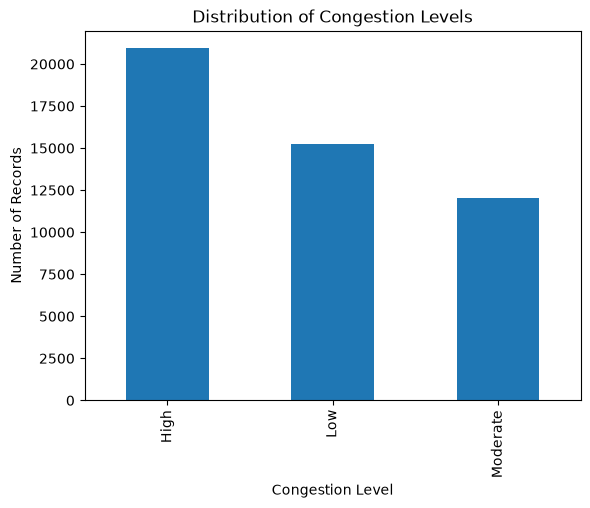

In [34]:
df['congestion_level'].value_counts().plot(kind='bar')

plt.xlabel('Congestion Level')
plt.ylabel('Number of Records')
plt.title('Distribution of Congestion Levels')
plt.show()

**Day × hour congestion heatmap**

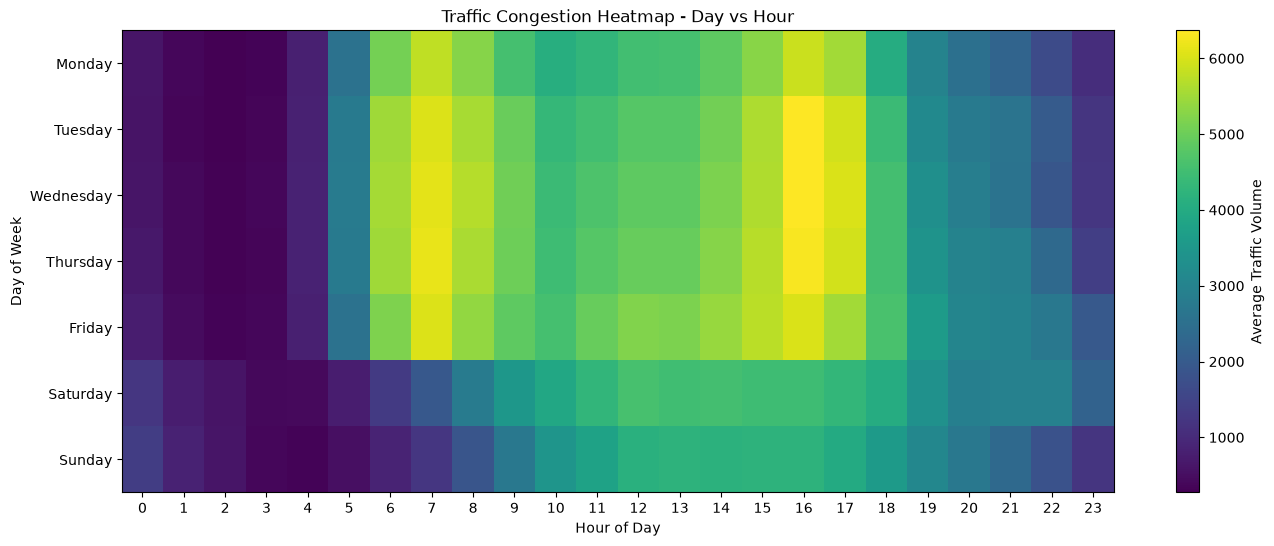

In [35]:
heatmap_data = df.pivot_table(
    values='traffic_volume',
    index='day_name',
    columns='hour',
    aggfunc='mean'
)

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(16,6))
plt.imshow(heatmap_data, aspect='auto')

plt.colorbar(label='Average Traffic Volume')
plt.xticks(range(24), range(24))
plt.yticks(range(7), day_order)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.title('Traffic Congestion Heatmap - Day vs Hour')

plt.show()  #It shows which day + hour combinations experience the heaviest traffic?

**Find the busiest hours**

In [36]:
df.groupby('hour')['traffic_volume'] \
  .mean() \
  .sort_values(ascending=False) \
  .head(10) #Top 10 busiest hours of day.

hour
16    5663.756539
17    5310.076048
15    5240.459907
14    4931.888776
7     4740.181337
12    4718.031730
13    4714.652836
8     4587.497115
11    4465.569231
9     4385.277502
Name: traffic_volume, dtype: float64

In [37]:
busiest_periods = (
    df.groupby(['day_name', 'hour'])['traffic_volume']
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

busiest_periods  #7 AM → Morning rush hour
#4 PM (hour 16) → Evening rush hour
#5 PM (hour 17) → Evening rush hour

,day_name,hour,traffic_volume
0,Wednesday,16,6367.467577
1,Tuesday,16,6366.796992
2,Thursday,16,6313.568421
3,Thursday,7,6168.611486
4,Wednesday,7,6120.721649
5,Tuesday,7,6043.778947
6,Friday,7,6038.904437
7,Friday,16,6026.752650
8,Wednesday,17,6018.631387
9,Thursday,17,5950.033457


In [38]:
df.head()


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celsius,year,month,day,hour,day_of_week,day_name,is_weekend,is_holiday,is_raining,congestion_level
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,2012,10,2,9,1,Tuesday,0,0,0,High
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,2012,10,2,10,1,Tuesday,0,0,0,High
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,2012,10,2,11,1,Tuesday,0,0,0,High
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,2012,10,2,12,1,Tuesday,0,0,0,High
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,2012,10,2,13,1,Tuesday,0,0,0,High


**Correlation analysis**

In [39]:
numeric_cols = [
    'temp_celsius',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'traffic_volume'
]

corr = df[numeric_cols].corr()

corr

,temp_celsius,rain_1h,snow_1h,clouds_all,hour,day_of_week,traffic_volume
temp_celsius,1.000000,0.177131,-0.158350,-0.101968,0.112048,-0.007824,0.130161
rain_1h,0.177131,1.000000,-0.051307,0.195470,-0.000295,-0.015047,-0.011281
snow_1h,-0.158350,-0.051307,1.000000,0.154595,-0.004537,-0.006123,-0.021780
clouds_all,-0.101968,0.195470,0.154595,1.000000,0.054522,-0.039816,0.067138
hour,0.112048,-0.000295,-0.004537,0.054522,1.000000,-0.003808,0.352300
day_of_week,-0.007824,-0.015047,-0.006123,-0.039816,-0.003808,1.000000,-0.149551
traffic_volume,0.130161,-0.011281,-0.021780,0.067138,0.352300,-0.149551,1.000000


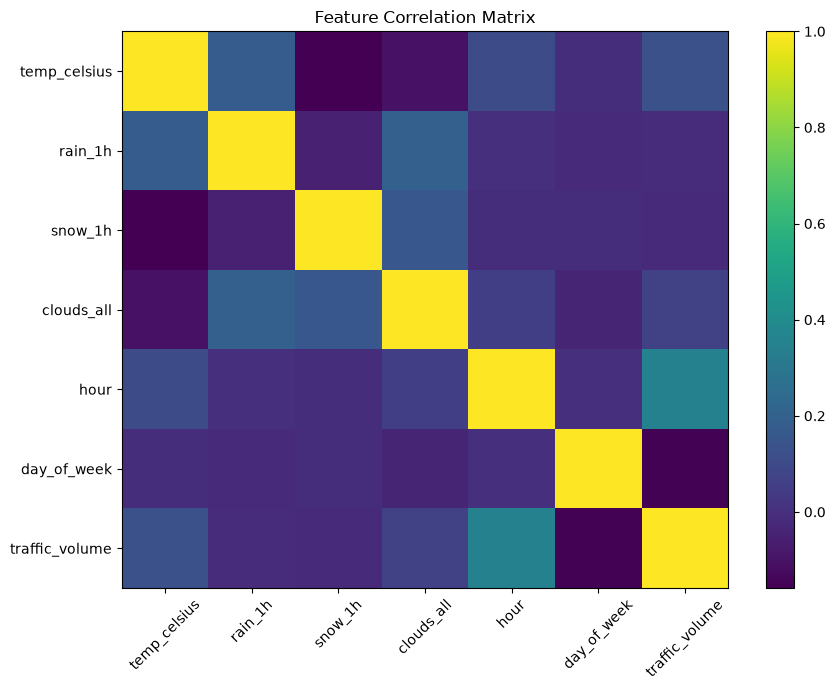

In [40]:
plt.figure(figsize=(9,7))
plt.imshow(corr, aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

**Feature engineering for the ML model**

Create lag variables : can actually help predict future traffic.

In [41]:
df = df.sort_values('date_time')

df['traffic_lag_1'] = df['traffic_volume'].shift(1)
df['traffic_lag_2'] = df['traffic_volume'].shift(2)
df['traffic_lag_24'] = df['traffic_volume'].shift(24)

Create rolling averages:

In [42]:
df['rolling_3h_avg'] = (
    df['traffic_volume']
      .shift(1)
      .rolling(3)
      .mean()
)

df['rolling_6h_avg'] = (
    df['traffic_volume']
      .shift(1)
      .rolling(6)
      .mean()
)

**Create the 1-hour-ahead target**

In [43]:
df['traffic_1h_ahead'] = df['traffic_volume'].shift(-1)

Lag and rolling operations naturally create missing rows.  #Remove missing values

In [44]:
df[[
    'traffic_lag_1',
    'traffic_lag_24',
    'rolling_3h_avg',
    'traffic_1h_ahead'
]].isnull().sum()

traffic_lag_1        1
traffic_lag_24      24
rolling_3h_avg       3
traffic_1h_ahead     1
dtype: int64

Modelling

In [45]:
model_df = df.dropna().copy()

baseline features

In [46]:
features = [
    'hour',
    'day_of_week',
    'month',
    'is_weekend',
    'is_holiday',
    'temp_celsius',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'traffic_lag_1',
    'traffic_lag_2',
    'traffic_lag_24',
    'rolling_3h_avg',
    'rolling_6h_avg'
]

X = model_df[features]
y = model_df['traffic_1h_ahead']

Train/test split - this is time-series data, don't use a random split as your primary evaluation.

In [47]:
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

Gradient Boosting baseline

In [51]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [52]:
y_pred = gb_model.predict(X_test)

Evaluate using MAE

In [53]:
from sklearn.metrics import mean_absolute_error

In [54]:
mae = mean_absolute_error(y_test, y_pred)

print("Gradient Boosting MAE:", mae)

Gradient Boosting MAE: 334.8198907574289


In [55]:
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 334.8198907574289
RMSE: 482.36423160720506
R²  : 0.9399257978478537


**Actual vs predicted graph**

In [56]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.head()

,Actual,Predicted
0,1713.0,1756.858555
1,1713.0,1271.523546
2,1068.0,1357.615667
3,611.0,798.269604
4,362.0,549.526403


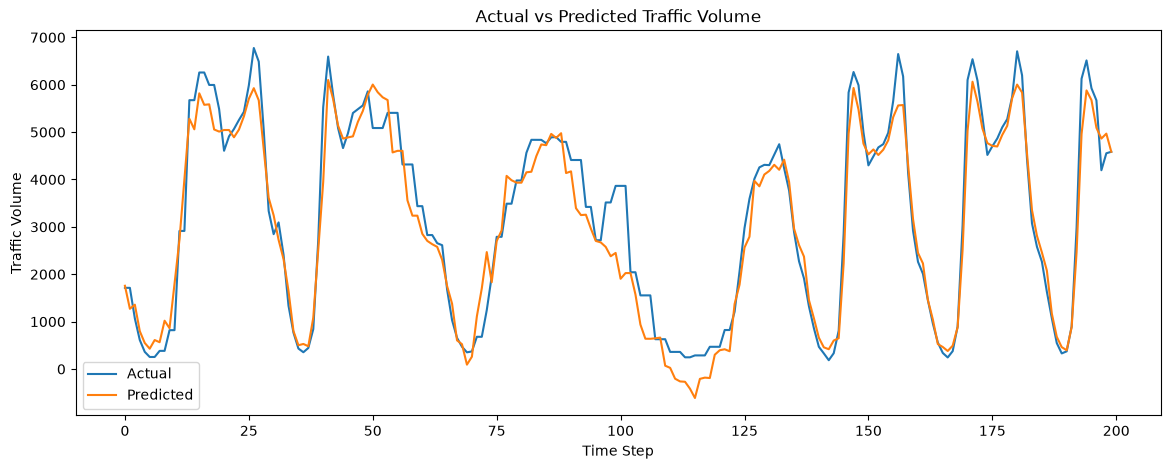

In [57]:
plt.figure(figsize=(14,5))

plt.plot(results['Actual'][:200], label='Actual')
plt.plot(results['Predicted'][:200], label='Predicted')

plt.xlabel('Time Step')
plt.ylabel('Traffic Volume')
plt.title('Actual vs Predicted Traffic Volume')
plt.legend()
plt.show()

**Feature importance** - which variables are influencing predictions




In [58]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': gb_model.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

importance

,Feature,Importance
9,traffic_lag_1,0.570713
0,hour,0.355365
10,traffic_lag_2,0.017566
3,is_weekend,0.016007
1,day_of_week,0.013836
12,rolling_3h_avg,0.013740
13,rolling_6h_avg,0.009740
11,traffic_lag_24,0.001312
5,temp_celsius,0.000654
2,month,0.000625


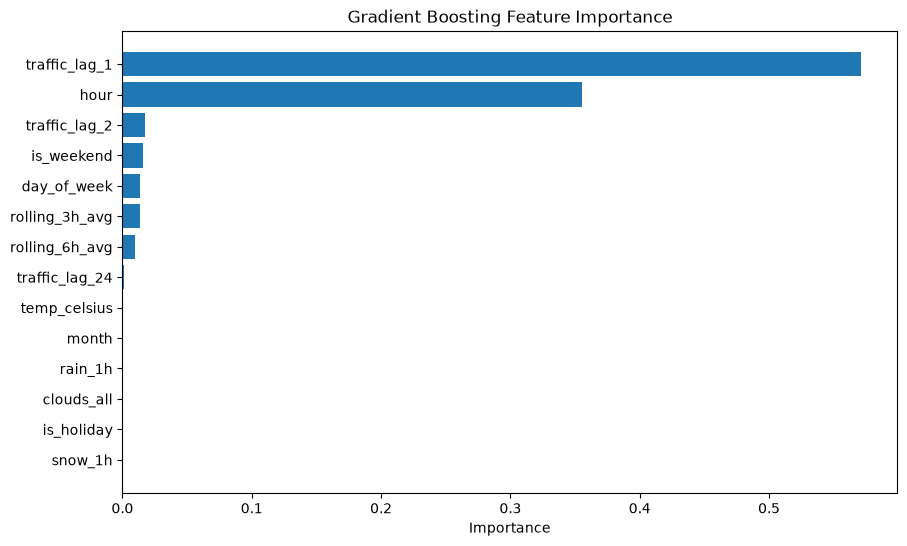

In [59]:
plt.figure(figsize=(10,6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel('Importance')
plt.title('Gradient Boosting Feature Importance')
plt.gca().invert_yaxis()

plt.show()

Save the cleaned dataset

In [60]:
df.to_csv(
    'metro_traffic_week1_processed.csv',
    index=False
)

In [61]:
model_df.to_csv(
    'metro_traffic_model_data.csv',
    index=False
)